In [7]:

from sklearn.linear_model import SGDClassifier
from sklearn.datasets import fetch_openml
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, precision_recall_curve, roc_curve, roc_auc_score
from sklearn.model_selection import cross_val_predict, StratifiedKFold, cross_val_score
from sklearn.base import clone, BaseEstimator
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.calibration import CalibratedClassifierCV
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import os

In [8]:

# Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist["data"], mnist["target"]

print("Shape of X (features):", X.shape)
print("Shape of y (labels):", y.shape)

c:\Users\Shourya Vardhan\OneDrive\Desktop\UPES\Sem-3\Applied Machine Learning\LAB_Github\.venv\Lib\site-packages\sklearn\datasets\_openml.py:95: RuntimeWarning: Invalid cache, redownloading file to C:\Users\Shourya Vardhan\scikit_learn_data\openml\openml.org\data/v1/download/52667/mnist_784.arff.gz
  warn(


Shape of X (features): (70000, 784)
Shape of y (labels): (70000,)


In [9]:

# Convert labels from string to integer
y = y.astype(np.uint8)

In [10]:

# Split the dataset
X_train, X_test = X[:20000], X[60000:]
y_train, y_test = y[:20000], y[60000:]

In [11]:
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (20000, 784)
Test set size: (10000, 784)


In [12]:

# ---------------------------------------------------------
# Visualize a few sample digits
# ---------------------------------------------------------
def plot_digit(data):
    image = data.reshape(28, 28)
    plt.imshow(image, cmap=mpl.cm.binary, interpolation="nearest")
    plt.axis("off")

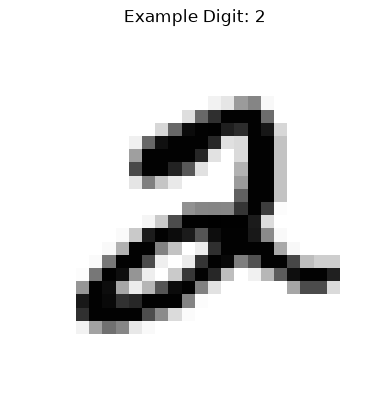

In [13]:

some_digit = X[5]
plot_digit(some_digit)
plt.title(f"Example Digit: {y[5]}")
plt.show()

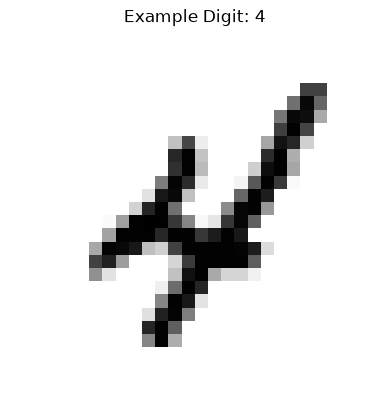

In [14]:

some_digit = X[9]
plot_digit(some_digit)
plt.title(f"Example Digit: {y[9]}")
plt.show()

In [15]:

# Function to plot digits in a grid
def plot_digits(instances, images_per_row=10, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    n_rows = (len(instances) - 1) // images_per_row + 1

    n_empty = n_rows * images_per_row - len(instances)
    padded_instances = np.concatenate([instances, np.zeros((n_empty, size * size))], axis=0)

    image_grid = padded_instances.reshape((n_rows, images_per_row, size, size))
    big_image = image_grid.transpose(0, 2, 1, 3).reshape(n_rows * size,
                                                         images_per_row * size)
    plt.imshow(big_image, cmap=mpl.cm.binary, **options)
    plt.axis("off")

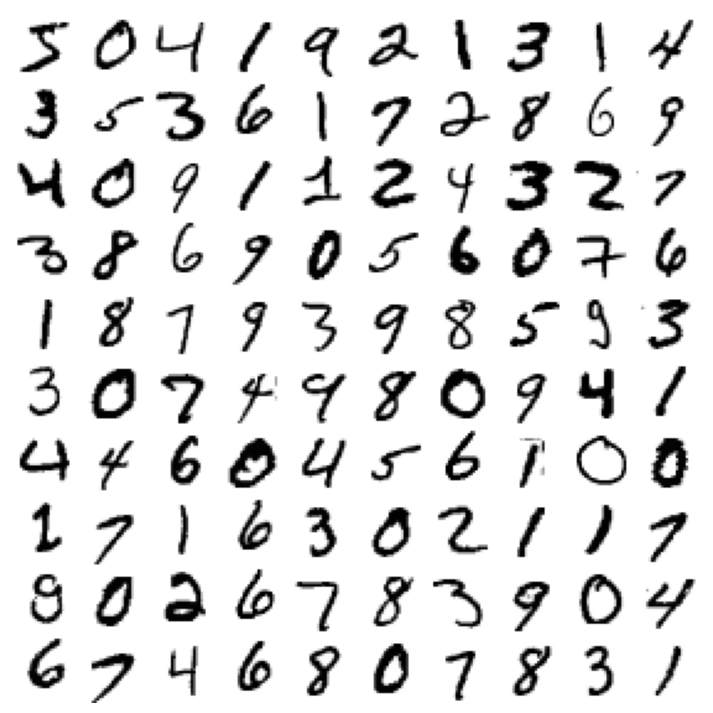

In [16]:

# Display the first 100 digits
plt.figure(figsize=(9, 9))
example_images = X[:100]  # assuming X contains your MNIST data
plot_digits(example_images, images_per_row=10)
plt.show()

In [17]:

y = y.astype(np.uint8)

In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.astype(np.float64))

In [19]:

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

In [20]:

# Initialize the SGD classifier
# We increased max_iter to improve the fit because maximum number of iteration was reached before convergence
sgd_clf = SGDClassifier(max_iter=5000, tol=1e-3, random_state=42)

# Train on the full multiclass labels
sgd_clf.fit(X_train, y_train)  # y_train has digits 0-9

# Predict a sample digit
sgd_clf.predict([some_digit])

array([4], dtype=uint8)

In [21]:

# Cross-validated accuracy for multiclass
cv_scores = cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")

print(cv_scores)        # Accuracy per fold
print(cv_scores.mean()) # Average accuracy
     

[0.90009107 0.90105534 0.90581806]
0.9023214910102486


In [22]:

# Cross-validated predictions on the multiclass labels
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train, cv=3)

# Confusion matrix for all classes (0 to 9)
cm = confusion_matrix(y_train, y_train_pred)

print(cm)
     

[[5221    0   17    6    4   33   35    6  199    1]
 [   0 6015   39   13    5   39    6    5  169   11]
 [  20   25 4958   75   67   23   56   34  319   15]
 [  26   17  110 4922    0  176   23   38  336   65]
 [   5   11   42    7 4903   10   37   22  279  143]
 [  25   18   29  145   56 4183   75   15  443   61]
 [  22   19   58    2   44   90 5143    8  115    0]
 [  19   10   55   20   40   11    3 5303  151  222]
 [  20   57   44   87    6  117   30    7 5047   45]
 [  25   14   21   58  127   35    0  154  298 4835]]


In [23]:

# Train it on training data
sgd_clf.fit(X_train, y_train)

#Predict labels for the training set
y_train_pred = sgd_clf.predict(X_train)

precision_score(y_train, y_train_pred, average=None)  # array of 10 numbers
recall_score(y_train, y_train_pred, average=None)
f1_score(y_train, y_train_pred, average=None)

array([0.96112232, 0.96490385, 0.91250917, 0.89657684, 0.92286062,
       0.86821226, 0.9506218 , 0.93546975, 0.7808    , 0.89218031])

Confusion matrix:
 [[5221    0   17    6    4   33   35    6  199    1]
 [   0 6015   39   13    5   39    6    5  169   11]
 [  20   25 4958   75   67   23   56   34  319   15]
 [  26   17  110 4922    0  176   23   38  336   65]
 [   5   11   42    7 4903   10   37   22  279  143]
 [  25   18   29  145   56 4183   75   15  443   61]
 [  22   19   58    2   44   90 5143    8  115    0]
 [  19   10   55   20   40   11    3 5303  151  222]
 [  20   57   44   87    6  117   30    7 5047   45]
 [  25   14   21   58  127   35    0  154  298 4835]]


<Figure size 800x800 with 0 Axes>

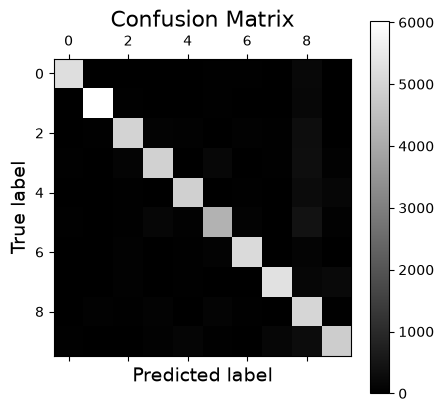

<Figure size 800x800 with 0 Axes>

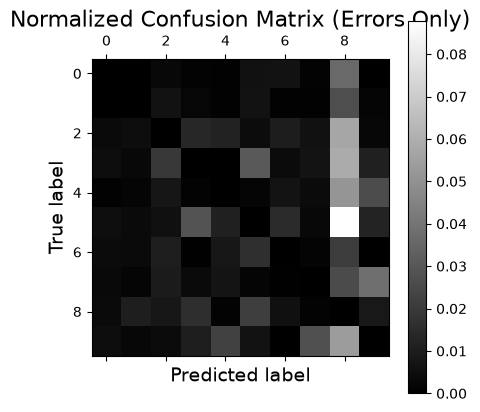

Precision at 90% threshold: 0.9001230012300123
Recall at 90% threshold: 0.7245544554455445


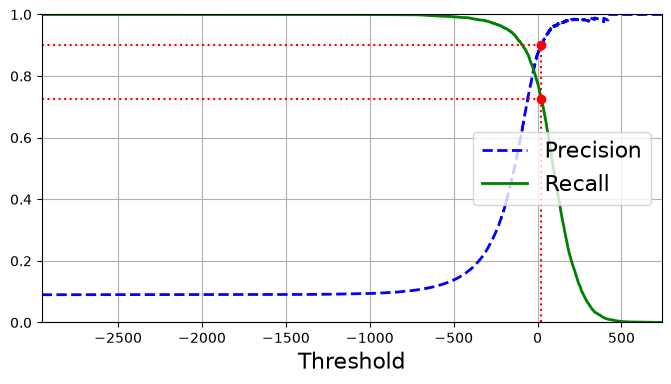

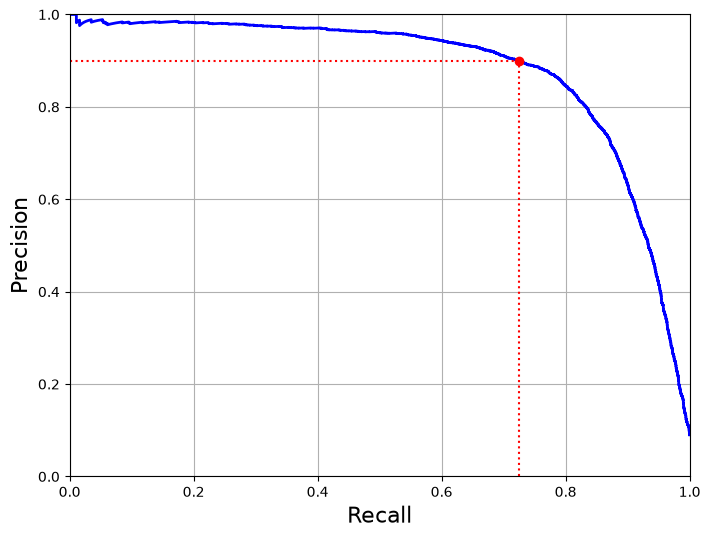

In [24]:

# 1. Get multiclass predictions using cross_val_predict
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train, cv=3)

# 2. Compute confusion matrix
conf_mx = confusion_matrix(y_train, y_train_pred)
print("Confusion matrix:\n", conf_mx)

# 3. Plot confusion matrix
plt.figure(figsize=(8, 8))
plt.matshow(conf_mx, cmap=plt.cm.gray)
plt.title("Confusion Matrix", fontsize=16)
plt.xlabel("Predicted label", fontsize=14)
plt.ylabel("True label", fontsize=14)
plt.colorbar()
plt.show()

# 4. Normalize confusion matrix by row sums (to highlight errors)
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums
np.fill_diagonal(norm_conf_mx, 0)  # set correct predictions to 0 for error focus

plt.figure(figsize=(8, 8))
plt.matshow(norm_conf_mx, cmap=plt.cm.gray)
plt.title("Normalized Confusion Matrix (Errors Only)", fontsize=16)
plt.xlabel("Predicted label", fontsize=14)
plt.ylabel("True label", fontsize=14)
plt.colorbar()
plt.show()
# --- Precision/Recall for class 5 (example) ---

# 1. Get decision scores for all classes using cross_val_predict
y_scores = cross_val_predict(sgd_clf, X_train, y_train, cv=3, method="decision_function")
# y_scores shape: (n_samples, n_classes)

# 2. Choose the class of interest (e.g., digit 5)
target_class = 5
# Create binary labels: True for class 5, False otherwise
y_train_5 = (y_train == target_class)

# 3. Extract scores for class 5
class_5_scores = y_scores[:, target_class]

# 4. Compute precision/recall curve for class 5
precisions, recalls, thresholds = precision_recall_curve(y_train_5, class_5_scores)

# 5. Find threshold for 90% precision
threshold_90_precision = thresholds[np.argmax(precisions >= 0.90)]
recall_90_precision = recalls[np.argmax(precisions >= 0.90)]

# 6. Make predictions using the chosen threshold
y_train_pred_90 = (class_5_scores >= threshold_90_precision)

# 7. Compute precision and recall at this threshold
print("Precision at 90% threshold:", precision_score(y_train_5, y_train_pred_90))
print("Recall at 90% threshold:", recall_score(y_train_5, y_train_pred_90))

# 8. Plot precision and recall vs threshold
def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
    plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
    plt.legend(loc="center right", fontsize=16)
    plt.xlabel("Threshold", fontsize=16)
    plt.grid(True)
    plt.axis([min(thresholds), max(thresholds), 0, 1])
     # Mark threshold for 90% precision
    plt.plot([threshold_90_precision, threshold_90_precision], [0., 0.9], "r:")
    plt.plot([min(thresholds), threshold_90_precision], [0.9, 0.9], "r:")
    plt.plot([min(thresholds), threshold_90_precision], [recall_90_precision, recall_90_precision], "r:")
    plt.plot([threshold_90_precision], [0.9], "ro")
    plt.plot([threshold_90_precision], [recall_90_precision], "ro")

plt.figure(figsize=(8, 4))
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)
plt.show()

# 9. Plot precision vs recall
def plot_precision_vs_recall(precisions, recalls):
    plt.plot(recalls, precisions, "b-", linewidth=2)
    plt.xlabel("Recall", fontsize=16)
    plt.ylabel("Precision", fontsize=16)
    plt.axis([0, 1, 0, 1])
    plt.grid(True)
    # Mark point for 90% precision
    plt.plot([recall_90_precision, recall_90_precision], [0., 0.9], "r:")
    plt.plot([0.0, recall_90_precision], [0.9, 0.9], "r:")
    plt.plot([recall_90_precision], [0.9], "ro")

plt.figure(figsize=(8, 6))
plot_precision_vs_recall(precisions, recalls)
plt.show()

c:\Users\Shourya Vardhan\OneDrive\Desktop\UPES\Sem-3\Applied Machine Learning\LAB_Github\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\Shourya Vardhan\OneDrive\Desktop\UPES\Sem-3\Applied Machine Learning\LAB_Github\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
c:\Users\Shourya Vardhan\OneDrive\Desktop\UPES\Sem-3\Applied Machine Learning\LAB_Github\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Weighted ROC-AUC: 0.9888
Micro ROC-AUC:    0.9897


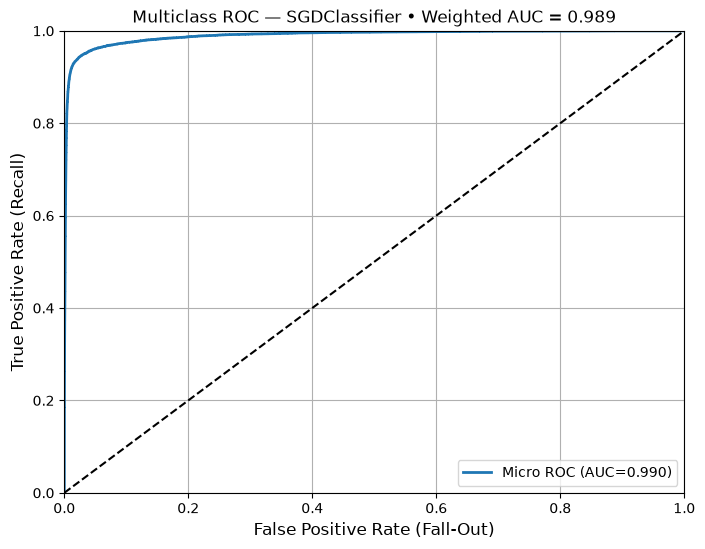

In [25]:
# --- Load dataset (MNIST example) ---
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X = X.astype(np.float32)
y = y.astype(np.int64)

# --- Split into train/test ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# --- Scale features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# --- Train SGDClassifier ---
sgd_clf = SGDClassifier(random_state=42, max_iter=1000, tol=1e-3)
# Wrap with CalibratedClassifierCV to get probabilities
sgd_clf_prob = CalibratedClassifierCV(sgd_clf, method="sigmoid", cv=3)
sgd_clf_prob.fit(X_train_scaled, y_train)

# --- Get probability scores for ROC ---
scores = sgd_clf_prob.predict_proba(X_test_scaled)  # shape: [n_samples, 10]

# --- Binarize true labels for multiclass ROC ---
Ybin = label_binarize(y_test, classes=np.arange(10))  # shape: [n_samples, 10]

# --- Compute micro-average ROC curve ---
fpr_micro, tpr_micro, _ = roc_curve(Ybin.ravel(), scores.ravel())

# --- Compute ROC-AUC scores ---
auc_weighted = roc_auc_score(y_test, scores, multi_class="ovr", average="weighted")
auc_micro    = roc_auc_score(y_test, scores, multi_class="ovr", average="micro")

print(f"Weighted ROC-AUC: {auc_weighted:.4f}")
print(f"Micro ROC-AUC:    {auc_micro:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr_micro, tpr_micro, linewidth=2, label=f"Micro ROC (AUC={auc_micro:.3f})")
plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line for random guess
plt.xlim(0, 1); plt.ylim(0, 1)
plt.xlabel("False Positive Rate (Fall-Out)", fontsize=12)
plt.ylabel("True Positive Rate (Recall)", fontsize=12)
plt.title(f"Multiclass ROC — SGDClassifier • Weighted AUC = {auc_weighted:.3f}")
plt.grid(True)
plt.legend(loc="lower right")
plt.show()

In [26]:
import time
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report
from scipy.stats import loguniform

# ------------------------------------------------------------
# Assume you already have X_train, X_test, y_train, y_test
# ------------------------------------------------------------

# Convert features to float32 for speed
X_train32 = X_train.astype("float32", copy=False)
X_test32  = X_test.astype("float32", copy=False)

# ------------------------------------------------------------
# 1) BASELINE MODEL (default settings)
# ------------------------------------------------------------
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SGDClassifier(random_state=42))
])

t0 = time.time()
baseline.fit(X_train32, y_train)
base_time = time.time() - t0

y_pred_base = baseline.predict(X_test32)
base_acc = accuracy_score(y_test, y_pred_base)

print(f"Baseline accuracy: {base_acc:.4f}  |  Time: {base_time:.1f}s\n")
# ------------------------------------------------------------
# 2) TUNED MODEL (subset + early stopping + random search)
# ------------------------------------------------------------
# Subsample ~30% of training data
rng = np.random.RandomState(42)
sub_frac = 0.30
sub_n = max(1000, int(sub_frac * len(X_train32)))
subset_idx = rng.choice(len(X_train32), size=sub_n, replace=False)

X_small = X_train32[subset_idx]
y_small = y_train[subset_idx]

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SGDClassifier(
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=5
    ))
])

param_distributions = {
    "clf__loss": ["hinge", "squared_hinge"],
    "clf__penalty": ["l2", "elasticnet"],
    "clf__alpha": loguniform(1e-6, 1e-2),
    "clf__tol": loguniform(1e-5, 1e-2),
    "clf__max_iter": [1000]
}

t1 = time.time()
search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_distributions,
    n_iter=24,
    cv=2,
    scoring="accuracy",
    n_jobs=-1,
    random_state=42
)
search.fit(X_small, y_small)
search_time = time.time() - t1

print(f"[Tuning done in {search_time:.1f}s]")
print("Best parameters:", search.best_params_)
print(f"Best subset CV accuracy: {search.best_score_:.4f}\n")

# ------------------------------------------------------------
# 3️⃣ Refit BEST model only on the SAME SUBSET (fast version)
# ------------------------------------------------------------
best_model = search.best_estimator_

t2 = time.time()
best_model.fit(X_small, y_small)   # ✅ train again only on subset
refit_time = time.time() - t2
print(f"[Subset refit done in {refit_time:.1f}s]")

# ------------------------------------------------------------
# 4️⃣ Evaluate on TEST set
# ------------------------------------------------------------
y_pred_best = best_model.predict(X_test32)
best_acc = accuracy_score(y_test, y_pred_best)

print(f"Tuned model accuracy: {best_acc:.4f}  |  Time: {refit_time:.1f}s\n")

# ------------------------------------------------------------
# 5️⃣ Compare with baseline
# ------------------------------------------------------------
improvement = best_acc - base_acc
print("📊 Performance comparison:")
print(f"  Baseline: {base_acc:.4f}")
print(f"  Tuned:    {best_acc:.4f}")
print(f"  ➜ Improvement: {improvement:+.4f}")

print("\nClassification report (tuned model):\n", classification_report(y_test, y_pred_best))

Baseline accuracy: 0.8957  |  Time: 265.6s

[Tuning done in 22.4s]
Best parameters: {'clf__alpha': np.float64(0.00015375920235481777), 'clf__loss': 'squared_hinge', 'clf__max_iter': 1000, 'clf__penalty': 'l2', 'clf__tol': np.float64(0.008105016126411584)}
Best subset CV accuracy: 0.9005

[Subset refit done in 1.0s]
Tuned model accuracy: 0.9026  |  Time: 1.0s

📊 Performance comparison:
  Baseline: 0.8957
  Tuned:    0.9026
  ➜ Improvement: +0.0070

Classification report (tuned model):
               precision    recall  f1-score   support

           0       0.93      0.97      0.95      1726
           1       0.94      0.96      0.95      1969
           2       0.92      0.89      0.90      1748
           3       0.90      0.85      0.87      1785
           4       0.92      0.91      0.91      1706
           5       0.86      0.85      0.86      1578
           6       0.91      0.96      0.94      1719
           7       0.92      0.92      0.92      1823
           8       0.87

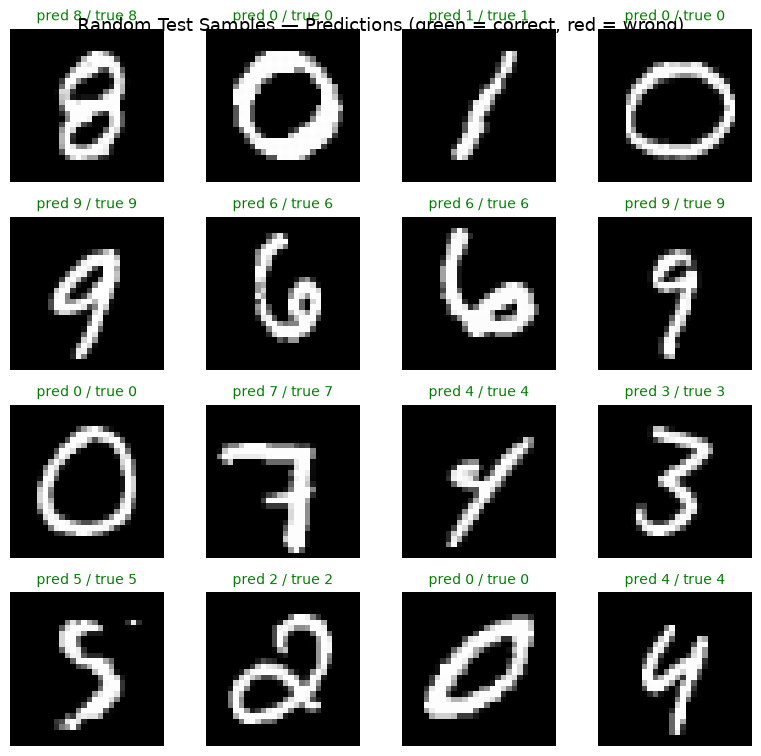

In [27]:

# 1️ Get predictions on the test set using the tuned model (pipeline handles scaling)
y_pred = best_model.predict(X_test)

# 2️ Select 16 random test images for visualization
rng = np.random.default_rng(42)                # for reproducibility
idx = rng.choice(len(X_test), size=16, replace=False)

# 3️ Reshape and extract the true and predicted labels
imgs = X_test[idx].reshape(-1, 28, 28)         # each image is 28×28 pixels
truth = y_test[idx]
preds = y_pred[idx]

# 4️ Display them with color-coded titles
plt.figure(figsize=(8, 8))
for i in range(16):
    ax = plt.subplot(4, 4, i + 1)
    ax.imshow(imgs[i], cmap="gray")
    ax.axis("off")
    ok = (preds[i] == truth[i])
    ax.set_title(
        f"pred {preds[i]} / true {truth[i]}",
        color=("green" if ok else "red"),
        fontsize=10
    )

plt.suptitle(
    "Random Test Samples — Predictions (green = correct, red = wrong)",
    y=0.93, fontsize=13
)
plt.tight_layout()
plt.show()

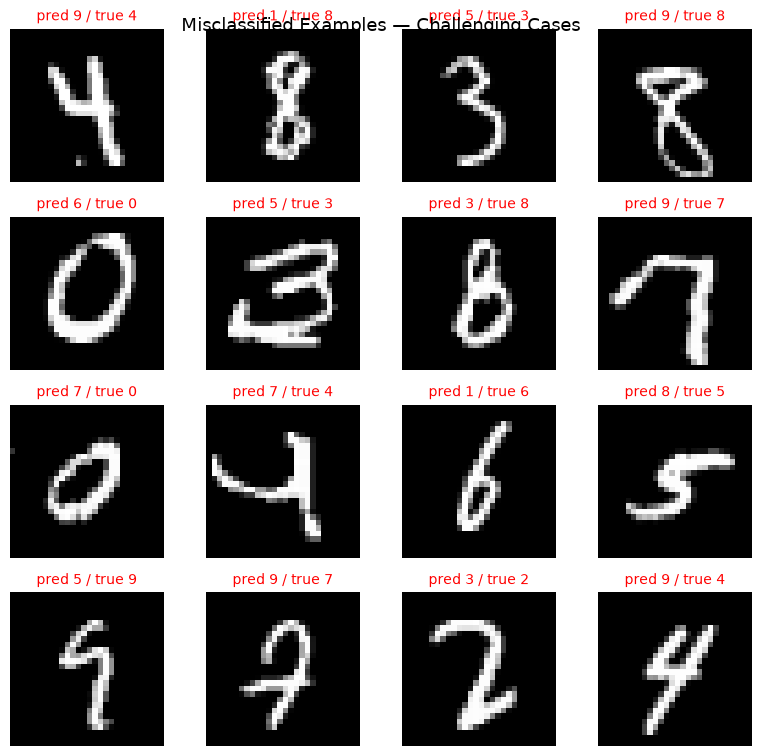

In [28]:

# 1️ Identify indices of all misclassified samples
bad = np.where(y_pred != y_test)[0]

# 2️ Select up to 16 for inspection
if len(bad) > 0:
    take = bad[:16] if len(bad) >= 16 else bad
    imgs_bad = X_test[take].reshape(-1, 28, 28)
    truth_bad = y_test[take]
    pred_bad = y_pred[take]

    # 3️ Plot these “hard” examples
    plt.figure(figsize=(8, 8))
    for i in range(len(take)):
        ax = plt.subplot(4, 4, i + 1)
        ax.imshow(imgs_bad[i], cmap="gray")
        ax.axis("off")
        ax.set_title(
            f"pred {pred_bad[i]} / true {truth_bad[i]}",
            color="red", fontsize=10
        )

    plt.suptitle("Misclassified Examples — Challenging Cases", y=0.93, fontsize=13)
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified examples in this sample.")